In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

np.random.seed(67)

df_rotterdam = pd.read_excel('rotterdam_dataset_02.xlsx')
df_rotterdam.head()

,Arrival_Date,Vessel_ID,Vessel_Type,Cargo_tons,Berth_Time_hr
0,2022-01-01 10:33:00,V000001,Container,10597,25.5
1,2022-01-01 19:24:00,V000002,Container,12878,19.2
2,2022-01-01 17:29:00,V000003,Container,11917,24.2
3,2022-01-01 06:23:00,V000004,Container,8757,16.7
4,2022-01-01 05:14:00,V000005,Container,27508,21.8


In [27]:
df_weight = df_rotterdam[['Vessel_Type', 'Cargo_tons']].copy()
df_weight_grouped = df_weight.groupby('Vessel_Type')
df_vessel_means = df_weight_grouped['Cargo_tons'].describe()
df_vessel_means

,count,mean,std,min,25%,50%,75%,max
Vessel_Type,,,,,,,,
Bulk,5133.0,39785.565556,16193.349694,4911.0,27896.0,37853.0,48969.0,144480.0
Container,10420.0,15765.674952,5635.666662,4125.0,11720.0,14809.5,18851.5,56006.0
Tanker,2317.0,51268.459215,15322.487237,19740.0,40182.0,49016.0,60381.0,128221.0


In [28]:
bulk_mean = df_vessel_means['mean'].iloc[0]
bulk_std = df_vessel_means['std'].iloc[0]

container_mean = df_vessel_means['mean'].iloc[1]
container_std = df_vessel_means['std'].iloc[1]

tanker_mean = df_vessel_means['mean'].iloc[2]
tanker_std = df_vessel_means['std'].iloc[2]

In [29]:
def lognormal_moments(mean, variance):
    lognormal_variance = np.log(1 + variance / mean**2)
    lognormal_mean = np.log(mean) - lognormal_variance / 2
    return lognormal_mean, np.sqrt(lognormal_variance)

mu_bulk, sigma_bulk = lognormal_moments(bulk_mean, bulk_std**2)
mu_container, sigma_container = lognormal_moments(container_mean, container_std**2)
mu_tanker, sigma_tanker = lognormal_moments(tanker_mean, tanker_std**2)

In [30]:
logNormDistEst_bulk = stats.lognorm(s=sigma_bulk, scale=np.exp(mu_bulk))
logNormDistEst_container = stats.lognorm(s=sigma_container, scale=np.exp(mu_container))
logNormDistEst_tanker = stats.lognorm(s=sigma_tanker, scale=np.exp(mu_tanker))

In [31]:
df_times = df_rotterdam[['Arrival_Date', 'Vessel_Type']].copy()
df_times = df_times.sort_values(by='Arrival_Date').reset_index(drop=True)
df_times.head()

,Arrival_Date,Vessel_Type
0,2022-01-01 00:04:00,Bulk
1,2022-01-01 00:55:00,Tanker
2,2022-01-01 01:13:00,Tanker
3,2022-01-01 02:08:00,Tanker
4,2022-01-01 02:59:00,Container


In [32]:
df_times_bulk = df_times[df_times['Vessel_Type'] == 'Bulk'].copy()
df_times_bulk['Time_diff'] = df_times_bulk['Arrival_Date'].diff()

df_times_tanker = df_times[df_times['Vessel_Type'] == 'Tanker'].copy()
df_times_tanker['Time_diff'] = df_times_tanker['Arrival_Date'].diff()

df_times_container = df_times[df_times['Vessel_Type'] == 'Container'].copy()
df_times_container['Time_diff'] = df_times_container['Arrival_Date'].diff()

In [33]:
iat_bulk = df_times_bulk['Time_diff'].dropna().dt.total_seconds() / 86400
lam_bulk = 1 / np.mean(iat_bulk)

iat_tanker = df_times_tanker['Time_diff'].dropna().dt.total_seconds() / 86400
lam_tanker = 1 / np.mean(iat_tanker)

iat_container = df_times_container['Time_diff'].dropna().dt.total_seconds() / 86400
lam_container = 1 / np.mean(iat_container)

print(lam_bulk)
print(lam_tanker)
print(lam_container)

4.683989422791703
2.113845873011044
9.508133971291867


In [34]:
def simPoissonProcess_bulk(lam, t):
    Nt = 0 # counter
    interArrivalTimeDist = stats.expon(scale = 1 / lam)
    time = interArrivalTimeDist.rvs()
    total_weight = 0
    while time < t:
        Nt += 1
        time += interArrivalTimeDist.rvs()
        total_weight += logNormDistEst_bulk.rvs()
    return Nt, total_weight

def simPoissonProcess_container(lam, t):
    Nt = 0 # counter
    interArrivalTimeDist = stats.expon(scale = 1 / lam)
    time = interArrivalTimeDist.rvs()
    total_weight = 0
    while time < t:
        Nt += 1
        time += interArrivalTimeDist.rvs()
        total_weight += logNormDistEst_container.rvs()
    return Nt, total_weight

def simPoissonProcess_tanker(lam, t):
    Nt = 0 # counter
    interArrivalTimeDist = stats.expon(scale = 1 / lam)
    time = interArrivalTimeDist.rvs()
    total_weight = 0
    while time < t:
        Nt += 1
        time += interArrivalTimeDist.rvs()
        total_weight += logNormDistEst_tanker.rvs()
    return Nt, total_weight

def simPoissonProcessSamplePath(lam, t):
    Nt = 0 # counter
    interArrivalTimeDist = stats.expon(scale = 1 / lam)
    time = interArrivalTimeDist.rvs()
    arrivalTimes = np.array([])

    while time < t:
        Nt += 1
        arrivalTimes = np.append(arrivalTimes, time)
        time += interArrivalTimeDist.rvs()
    return arrivalTimes 

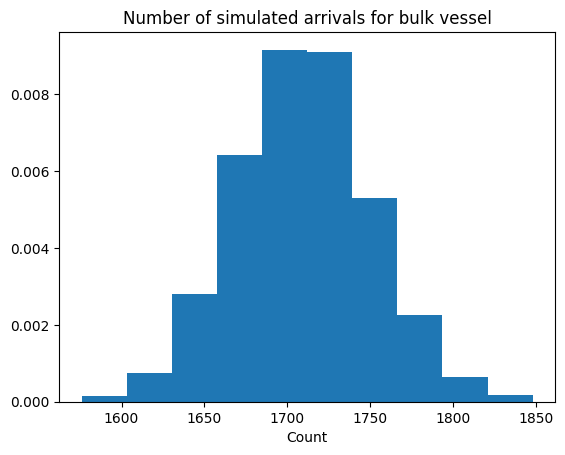

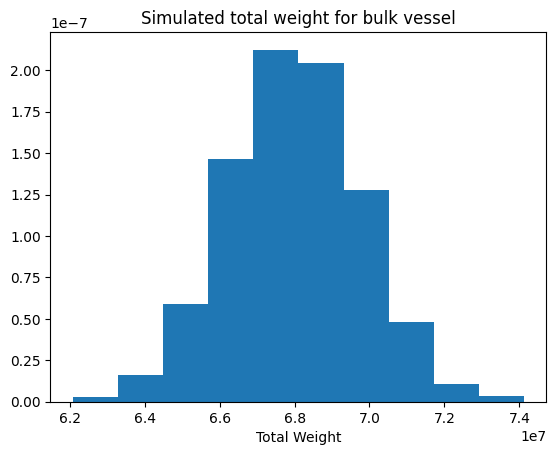

In [35]:
t = 365 # days in a year
nrRuns = 5000

N_Bt = np.zeros(nrRuns)
S_Bt = np.zeros(nrRuns)
for i in range(nrRuns):
    N_Bt[i], S_Bt[i] = simPoissonProcess_bulk(lam_bulk, t)

plt.figure()
plt.hist(N_Bt, density=True)
plt.title('Number of simulated arrivals for bulk vessel')
plt.xlabel('Count')
plt.show()

plt.figure()
plt.hist(S_Bt, density=True)
plt.title('Simulated total weight for bulk vessel')
plt.xlabel('Total Weight')
plt.show()

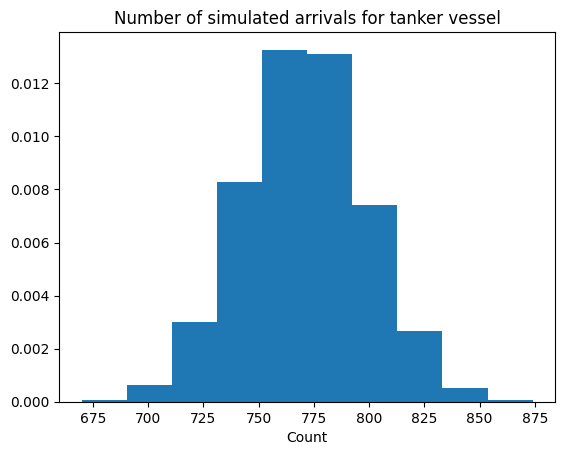

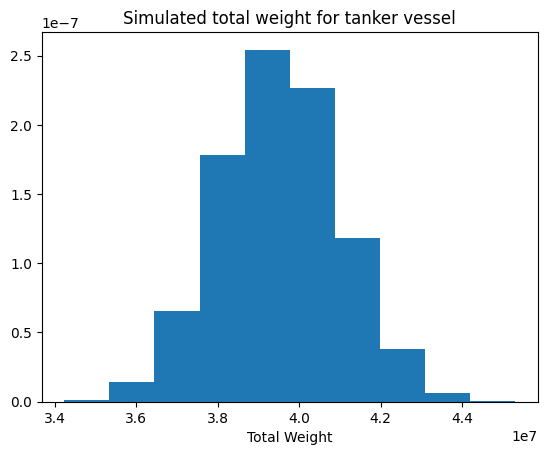

In [36]:
N_Tt = np.zeros(nrRuns)
S_Tt = np.zeros(nrRuns)
for i in range(nrRuns):
    N_Tt[i], S_Tt[i] = simPoissonProcess_tanker(lam_tanker, t)

plt.figure()
plt.hist(N_Tt, density=True)
plt.title('Number of simulated arrivals for tanker vessel')
plt.xlabel('Count')
plt.show()

plt.figure()
plt.hist(S_Tt, density=True)
plt.title('Simulated total weight for tanker vessel')
plt.xlabel('Total Weight')
plt.show()

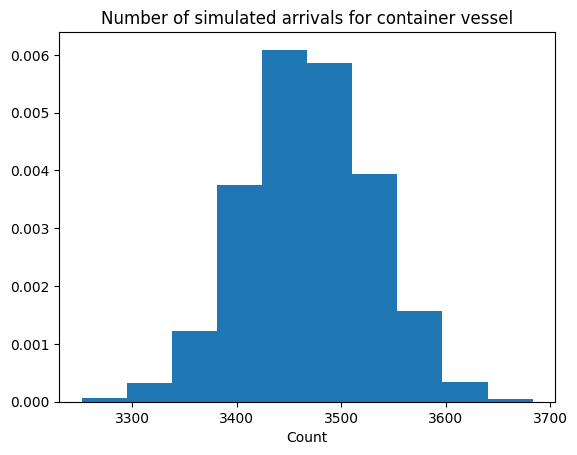

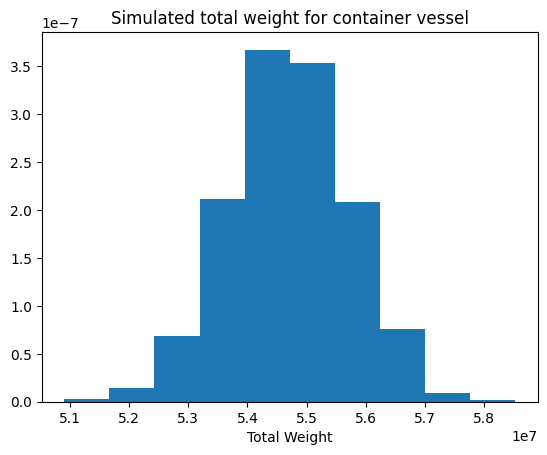

In [37]:
N_Ct = np.zeros(nrRuns)
S_Ct = np.zeros(nrRuns)
for i in range(nrRuns):
    N_Ct[i], S_Ct[i] = simPoissonProcess_container(lam_container, t)

plt.figure()
plt.hist(N_Ct, density=True)
plt.title('Number of simulated arrivals for container vessel')
plt.xlabel('Count')
plt.show()

plt.figure()
plt.hist(S_Ct, density=True)
plt.title('Simulated total weight for container vessel')
plt.xlabel('Total Weight')
plt.show()

In [38]:
N_total_t = N_Ct + N_Tt + N_Bt
S_total_t = S_Ct + S_Tt + S_Bt

results_N = {'N_Bt': N_Bt, 'N_Ct': N_Ct, 'N_Tt': N_Tt, 'Nt': N_total_t}
results_S = {'S_Bt': S_Bt, 'S_Ct': S_Ct, 'S_Tt': S_Tt, 'St': S_total_t}

for name, result in results_N.items():
    print(f'{name} mean: {result.mean()}, std: {result.std()}, 95% quantile = {np.quantile(result, 0.95)}')

for name, result in results_S.items():
    print(f'{name} mean: {result.mean()}, std: {result.std()}, 95% quantile = {np.quantile(result, 0.95)}')

N_Bt mean: 1709.4162, std: 41.084753590109315, 95% quantile = 1778.0
N_Ct mean: 3469.376, std: 60.42255062474605, 95% quantile = 3569.0
N_Tt mean: 770.8334, std: 27.616300339473426, 95% quantile = 817.0
Nt mean: 5949.6256, std: 78.19472248585578, 95% quantile = 6079.0
S_Bt mean: 68000440.8812592, std: 1751235.3979309695, 95% quantile = 70883576.50066066
S_Ct mean: 54704944.01307391, std: 1008059.8483498286, 95% quantile = 56369400.69455628
S_Tt mean: 39518185.75386816, std: 1475437.370237648, 95% quantile = 41966581.12160898
St mean: 162223570.64820126, std: 2524615.3551631435, 95% quantile = 166481523.7749565


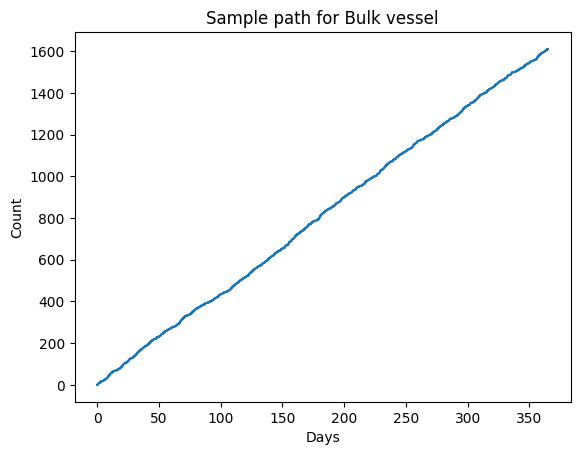

In [39]:
t = 365
arrTimes = simPoissonProcessSamplePath(lam_bulk, t)
xs = np.append(np.append([0], arrTimes), t)
ys = np.append(range(0, len(arrTimes) + 1), len(arrTimes))

plt.figure()
plt.step(xs, ys, where= 'post')
plt.title('Sample path for Bulk vessel')
plt.xlabel('Days')
plt.ylabel('Count')
plt.show()

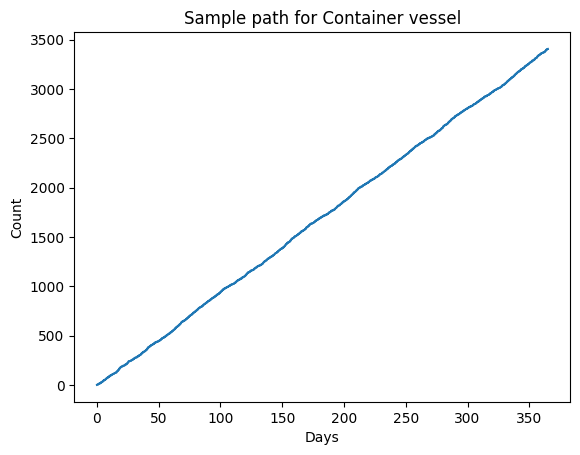

In [40]:
t = 365
arrTimes = simPoissonProcessSamplePath(lam_container, t)
xs = np.append(np.append([0], arrTimes), t)
ys = np.append(range(0, len(arrTimes) + 1), len(arrTimes))

plt.figure()
plt.step(xs, ys, where= 'post')
plt.title('Sample path for Container vessel')
plt.xlabel('Days')
plt.ylabel('Count')
plt.show()

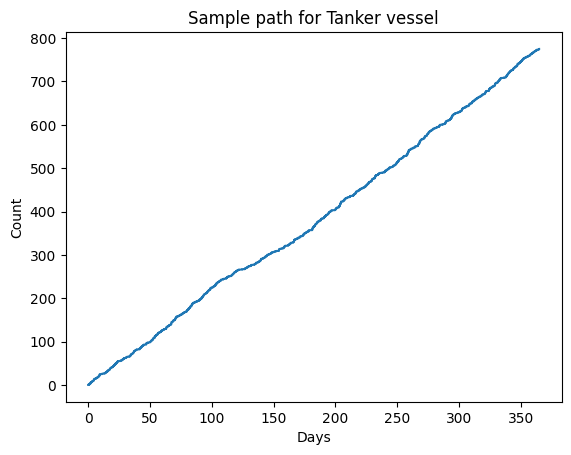

In [41]:
t = 365
arrTimes = simPoissonProcessSamplePath(lam_tanker, t)
xs = np.append(np.append([0], arrTimes), t)
ys = np.append(range(0, len(arrTimes) + 1), len(arrTimes))

plt.figure()
plt.step(xs, ys, where= 'post')
plt.title('Sample path for Tanker vessel')
plt.xlabel('Days')
plt.ylabel('Count')
plt.show()

In [42]:
nrRunsExceed = 100000
simResultExceed = np.zeros(nrRunsExceed)
for i in range(nrRunsExceed):
    simResultExceed[i] = simPoissonProcess_bulk(lam_bulk , 1)[1] + simPoissonProcess_container(lam_container, 1)[1] + simPoissonProcess_tanker(lam_tanker, 1)[1] > 650000

print(simResultExceed.mean())

halfWidth = 1.96 * np.std(simResultExceed) / np.sqrt(nrRunsExceed)
ci = (np.mean(simResultExceed) - halfWidth, np.mean(simResultExceed) + halfWidth)
ci

0.06928


(np.float64(0.06770612754711647), np.float64(0.07085387245288352))